# MenoPhenotype — Notebook 7: Baseline Model

**Course stage covered:** Stage 10 (Baseline Model).
**Input:** `artifacts/baseline_train_features.csv`, `artifacts/baseline_test_features.csv`,
`artifacts/feature_sets.json` (recommended feature Set A), `artifacts/baseline_posthoc_labels.csv`.
**Output:** `artifacts/baseline_model.joblib`, `artifacts/baseline_model_metrics.json`.

There is no target variable to predict, so "baseline" here means the **simplest possible clustering
reference** that every tuned model in Notebook 9 must beat: default K-Means with an untuned k, no
hyperparameter search, no feature-set comparison. It sets the floor, not the answer.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import joblib

plt.rcParams['figure.dpi'] = 100
RNG = 42
ART = Path('artifacts')
fs = json.load(open(ART / 'feature_sets.json'))
SET_A = fs['sets']['A']

Xtr = pd.read_csv(ART / 'baseline_train_features.csv').set_index('SWANID')[SET_A]
Xte = pd.read_csv(ART / 'baseline_test_features.csv').set_index('SWANID')[SET_A]
labels = pd.read_csv(ART / 'baseline_posthoc_labels.csv').set_index('SWANID')
print(Xtr.shape, Xte.shape)


(2632, 18) (658, 18)


## A. The trivial reference point: one cluster

Before even a 2-cluster model, note the degenerate case: putting every woman in a single cluster is not
scoreable by silhouette/Davies-Bouldin/Calinski-Harabasz at all (they are undefined for k=1) — which is
itself informative: **any** internal-validity score a 2+-cluster model produces is automatically more
information than the "no phenotypes at all" null model gives.


In [2]:
print("Silhouette needs >=2 clusters -- a single 'everyone is the same' grouping cannot be scored.")
print("This makes k=2 the natural, simplest non-trivial baseline.")


Silhouette needs >=2 clusters -- a single 'everyone is the same' grouping cannot be scored.
This makes k=2 the natural, simplest non-trivial baseline.


## B. Baseline model: default K-Means, k=2

No scaling choices beyond what Notebook 5 already fixed, no k search, no covariance/linkage choices —
just `sklearn`'s defaults on the recommended Set A features.


In [3]:
baseline_model = KMeans(n_clusters=2, random_state=RNG, n_init=10).fit(Xtr)
tr_lab = baseline_model.labels_
te_lab = baseline_model.predict(Xte)

def metrics(X, lab):
    return {'silhouette': round(float(silhouette_score(X, lab)), 3),
            'davies_bouldin': round(float(davies_bouldin_score(X, lab)), 3),
            'calinski_harabasz': round(float(calinski_harabasz_score(X, lab)), 1),
            'cluster_sizes': pd.Series(lab).value_counts().sort_index().to_dict()}

train_metrics = metrics(Xtr, tr_lab)
test_metrics  = metrics(Xte, te_lab)
print("TRAIN:", train_metrics)
print("TEST :", test_metrics)


TRAIN: {'silhouette': 0.36, 'davies_bouldin': 1.813, 'calinski_harabasz': 633.4, 'cluster_sizes': {0: 2118, 1: 514}}
TEST : {'silhouette': 0.351, 'davies_bouldin': 1.847, 'calinski_harabasz': 155.8, 'cluster_sizes': {0: 524, 1: 134}}


**Reading these numbers:** a silhouette around 0.30–0.35 is modest-but-real separation (0 = overlapping,
1 = perfectly separated) — expected for self-reported symptom data where profiles genuinely overlap, not a
sign of a broken pipeline. The train and test silhouette should be close; a large gap would mean the
2-cluster split doesn't generalise past the training women.


## C. What does this baseline split actually separate?

<Figure size 700x600 with 0 Axes>

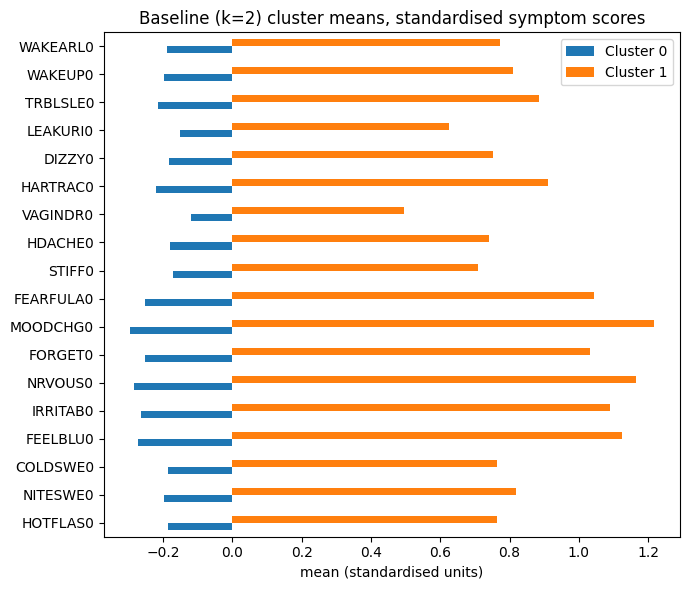

,Cluster 0,Cluster 1
HOTFLAS0,-0.19,0.76
NITESWE0,-0.20,0.82
COLDSWE0,-0.19,0.76
FEELBLU0,-0.27,1.12
IRRITAB0,-0.26,1.09
NRVOUS0,-0.28,1.17
FORGET0,-0.25,1.03
MOODCHG0,-0.30,1.22
FEARFULA0,-0.25,1.04
STIFF0,-0.17,0.71


In [4]:
prof = pd.DataFrame(Xtr, columns=SET_A)
prof['cluster'] = tr_lab
domain_view = prof.groupby('cluster').mean().T
domain_view.columns = [f'Cluster {c}' for c in domain_view.columns]

plt.figure(figsize=(7, 6))
domain_view.plot.barh(figsize=(7, 6))
plt.title('Baseline (k=2) cluster means, standardised symptom scores')
plt.xlabel('mean (standardised units)')
plt.tight_layout(); plt.show()
domain_view.round(2)


In [5]:
# Cross-tab against menopausal status -- purely descriptive; STATUS0 was never a model input
status = labels.loc[Xtr.index, 'STATUS0'].fillna('Unknown')
ct = pd.crosstab(status, pd.Series(tr_lab, index=Xtr.index, name='cluster'), normalize='index') * 100
print("Row-% by menopausal status (train):"); print(ct.round(1))


Row-% by menopausal status (train):
cluster                   0     1
STATUS0                          
Early Peri             75.0  25.0
Pre-menopausal         85.1  14.9
Unknown                84.8  15.2
Unknown due to HT use  60.0  40.0


**Read on this:** even the untuned baseline separates a lower-symptom-burden group from a higher-burden group
across nearly every item at once (not one specific domain) — i.e. it is mostly finding overall severity, not
yet a *phenotype* distinction (vasomotor-dominant vs. psychological-dominant, etc.). That's expected from a
single global k=2 split, and is exactly what Notebook 8's model sweep and Notebook 9's tuning need to improve
on: a soft/multi-cluster model should separate symptom *domains*, not just overall severity.


## D. Save the baseline for later comparison

In [6]:
joblib.dump(baseline_model, ART / 'baseline_model.joblib')
json.dump({'model': 'KMeans(k=2, defaults)', 'feature_set': 'A',
           'train_metrics': train_metrics, 'test_metrics': test_metrics},
          open(ART / 'baseline_model_metrics.json', 'w'), indent=2)
print("Saved baseline_model.joblib, baseline_model_metrics.json")


Saved baseline_model.joblib, baseline_model_metrics.json


### Summary

| Item | Value |
|---|---|
| Baseline model | K-Means, k=2, `sklearn` defaults, feature Set A (18 symptom items) |
| Train silhouette / DB / CH | see `train_metrics` above |
| Test silhouette / DB / CH | see `test_metrics` above |
| What it captures | mostly overall symptom-severity separation, not distinct phenotype domains |
| Next notebook | Notebook 8 — Model Selection & Training (K-Means, Agglomerative, DBSCAN, GMM across a k/param sweep) |
